In [11]:
!unzip archive.zip

Archive:  archive.zip
  inflating: fake_job_postings.csv   


Loading data...
=========== 1. COMBINED MODEL ===========
              precision    recall  f1-score   support

           0       0.99      0.93      0.96      5104
           1       0.38      0.80      0.51       260

    accuracy                           0.93      5364
   macro avg       0.68      0.87      0.74      5364
weighted avg       0.96      0.93      0.94      5364



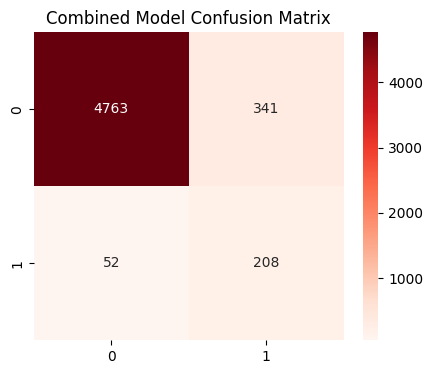


=========== 2. TEXT ONLY MODEL ===========
              precision    recall  f1-score   support

           0       0.99      0.95      0.97      5104
           1       0.42      0.78      0.54       260

    accuracy                           0.94      5364
   macro avg       0.70      0.86      0.76      5364
weighted avg       0.96      0.94      0.95      5364


=========== 3. STRUCTURED ONLY MODEL ===========
              precision    recall  f1-score   support

           0       0.98      0.82      0.89      5104
           1       0.15      0.63      0.25       260

    accuracy                           0.81      5364
   macro avg       0.57      0.73      0.57      5364
weighted avg       0.94      0.81      0.86      5364



In [12]:
# My Machine Learning Assignment - Task B1
# Dataset: Fake Job Postings

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset
print("Loading data...")
df = pd.read_csv('fake_job_postings.csv')
df = df.dropna(subset=['description']) # Drop missing text

# 2. Define X (features) and y (target)
X = df[['description', 'has_company_logo']]
y = df['fraudulent']

# 3. Split into train and test (70/30)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=7, stratify=y)

# 4. Combined Model (Text + Structured)
print("=========== 1. COMBINED MODEL ===========")
preprocessor = ColumnTransformer(
    transformers=[
        ('text_data', TfidfVectorizer(max_features=3000), 'description'),
        ('cat_data', OneHotEncoder(handle_unknown='ignore'), ['has_company_logo'])
    ])

combined_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(class_weight='balanced', max_iter=1000))
])

combined_pipeline.fit(X_train, y_train)
combined_predictions = combined_pipeline.predict(X_test)
print(classification_report(y_test, combined_predictions))

# Graph
cm = confusion_matrix(y_test, combined_predictions)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds')
plt.title('Combined Model Confusion Matrix')
plt.show()

# 5. Text Only Model
print("\n=========== 2. TEXT ONLY MODEL ===========")
text_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=3000)),
    ('classifier', LogisticRegression(class_weight='balanced', max_iter=1000))
])
text_pipeline.fit(X_train['description'], y_train)
text_predictions = text_pipeline.predict(X_test['description'])
print(classification_report(y_test, text_predictions))

# 6. Structured Only Model
print("\n=========== 3. STRUCTURED ONLY MODEL ===========")
struct_pipeline = Pipeline([
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
    ('classifier', LogisticRegression(class_weight='balanced'))
])
struct_pipeline.fit(X_train[['has_company_logo']], y_train)
struct_predictions = struct_pipeline.predict(X_test[['has_company_logo']])
print(classification_report(y_test, struct_predictions))